# 05 - Polynomial Regression

## Aim
Use polynomial features to model a curved relationship. This is included as an extra regression exercise because a straight line is not suitable for every continuous dataset.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

## 2. Load the curved dataset

In [2]:
data = pd.read_csv("datasets/P029a.txt", sep="\t")
display(data)

,Y,X
0,1,-7
1,14,-6
2,25,-5
3,34,-4
4,41,-3
5,46,-2
6,49,-1
7,50,0
8,49,1
9,46,2


## 3. Prepare X and Y

In [3]:
X = data[["X"]]
y = data["Y"]
print("Feature shape:", X.shape)

Feature shape: (15, 1)


## 4. Transform X into polynomial features

In [4]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)

print("Feature names:", poly.get_feature_names_out(["X"]))
display(pd.DataFrame(X_poly, columns=poly.get_feature_names_out(["X"])).head())

Feature names: ['X' 'X^2']


,X,X^2
0,-7.0,49.0
1,-6.0,36.0
2,-5.0,25.0
3,-4.0,16.0
4,-3.0,9.0


## 5. Fit the polynomial regression model

In [5]:
model = LinearRegression()
model.fit(X_poly, y)

print(f"Intercept = {model.intercept_:.4f}")
print(f"Linear coefficient = {model.coef_[0]:.4f}")
print(f"Quadratic coefficient = {model.coef_[1]:.4f}")

Intercept = 50.0000
Linear coefficient = 0.0000
Quadratic coefficient = -1.0000


## 6. Evaluate the model

In [6]:
y_hat = model.predict(X_poly)
print(f"MSE = {mean_squared_error(y, y_hat):.6f}")
print(f"R²  = {r2_score(y, y_hat):.4f}")

MSE = 0.000000
R²  = 1.0000


## 7. Visualize the curve

/opt/pyvenv/lib/python3.13/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


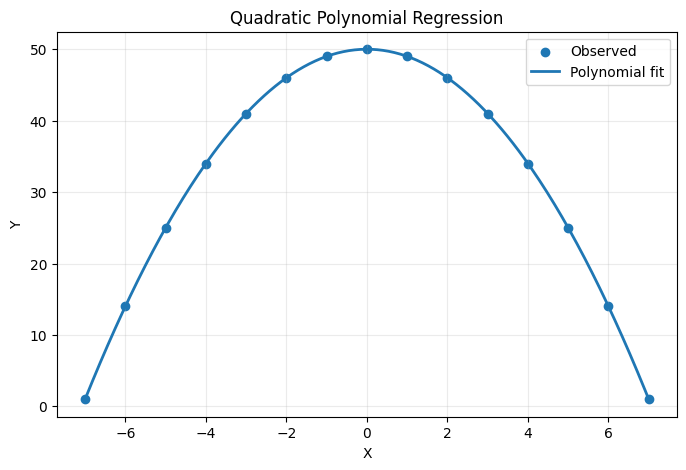

In [7]:
x_grid = np.linspace(X["X"].min(), X["X"].max(), 300).reshape(-1, 1)
y_grid = model.predict(poly.transform(x_grid))

plt.figure(figsize=(8, 5))
plt.scatter(X["X"], y, label="Observed")
plt.plot(x_grid.ravel(), y_grid, linewidth=2, label="Polynomial fit")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Quadratic Polynomial Regression")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Conclusion
Polynomial regression still uses linear regression internally, but it expands the input into polynomial terms so that a curved relationship can be represented.